In [1]:
import pandas as pd
import numpy as np

# ---- Input ----
FLIGHTS_CSV = "opensky_flights_yesterday.csv"   # produced by get_data_from_open_sky.ipynb
AIRPORT_FILTER = None  # e.g., "LHBP" (Budapest). Set None to keep all airports.

# ---- Turnaround pairing constraints ----
MIN_TA_MINUTES = 15      # ignore impossible short turnarounds
MAX_TA_HOURS   = 8       # ignore very long gaps (overnight / maintenance) unless you want them

# ---- Proxy offsets for on/off-block (in minutes) ----
EPS_ONBLOCK_MIN = 2
EPS_OFFBLOCK_MIN = 2

df = pd.read_csv(FLIGHTS_CSV)
print("Flights loaded:", len(df))
print("Columns:", list(df.columns))


Flights loaded: 117935
Columns: ['icao24', 'firstSeen', 'estDepartureAirport', 'lastSeen', 'estArrivalAirport', 'callsign', 'estDepartureAirportHorizDistance', 'estDepartureAirportVertDistance', 'estArrivalAirportHorizDistance', 'estArrivalAirportVertDistance', 'departureAirportCandidatesCount', 'arrivalAirportCandidatesCount']


In [2]:

# Basic cleaning + timestamps
needed = ["icao24","firstSeen","lastSeen","estDepartureAirport","estArrivalAirport","callsign"]
for c in needed:
    if c not in df.columns:
        raise ValueError(f"Missing required column: {c}")

df["firstSeen"] = pd.to_numeric(df["firstSeen"], errors="coerce")
df["lastSeen"]  = pd.to_numeric(df["lastSeen"], errors="coerce")

df = df.dropna(subset=["icao24","firstSeen","lastSeen","estDepartureAirport","estArrivalAirport"])
df["firstSeen_dt"] = pd.to_datetime(df["firstSeen"].astype(int), unit="s", utc=True)
df["lastSeen_dt"]  = pd.to_datetime(df["lastSeen"].astype(int), unit="s", utc=True)

# Optional: focus on one airport
if AIRPORT_FILTER:
    df = df[(df["estDepartureAirport"] == AIRPORT_FILTER) | (df["estArrivalAirport"] == AIRPORT_FILTER)].copy()
    print("After airport filter:", len(df))

# Keep only sensible flights (arrival after departure)
df = df[df["lastSeen_dt"] >= df["firstSeen_dt"]].copy()

# Normalize callsign
df["callsign"] = df["callsign"].astype(str).str.strip().replace({"nan": np.nan})

df = df.sort_values(["icao24","firstSeen_dt"]).reset_index(drop=True)
df.head()


,icao24,firstSeen,estDepartureAirport,lastSeen,estArrivalAirport,callsign,estDepartureAirportHorizDistance,estDepartureAirportVertDistance,estArrivalAirportHorizDistance,estArrivalAirportVertDistance,departureAirportCandidatesCount,arrivalAirportCandidatesCount,firstSeen_dt,lastSeen_dt
0,000001,1765411204,MMMX,1765440507,VI20,UGLY31,13494.0,178.0,4560.0,943.0,0,0,2025-12-11 00:00:04+00:00,2025-12-11 08:08:27+00:00
1,000001,1765441620,VI20,1765442488,VI20,VTFSV,2063.0,920.0,5375.0,851.0,0,0,2025-12-11 08:27:00+00:00,2025-12-11 08:41:28+00:00
2,000001,1765488298,KECG,1765493486,6NC9,CRSBO41,129.0,57.0,8738.0,1514.0,2,3,2025-12-11 21:24:58+00:00,2025-12-11 22:51:26+00:00
3,0000ba,1765411277,KECG,1765412789,KECG,BALLOON,4537.0,224.0,4528.0,224.0,2,6,2025-12-11 00:01:17+00:00,2025-12-11 00:26:29+00:00
4,0000ba,1765460918,KECG,1765469169,KECG,BALLOON,4567.0,270.0,4548.0,263.0,2,6,2025-12-11 13:48:38+00:00,2025-12-11 16:06:09+00:00


In [3]:

# Pair consecutive flights per aircraft to create turnarounds
pairs = []
for icao, g in df.groupby("icao24", sort=False):
    g = g.sort_values("firstSeen_dt")
    g_next = g.shift(-1)

    # A valid turnaround happens at the airport where inbound arrives and outbound departs
    same_airport = (g["estArrivalAirport"] == g_next["estDepartureAirport"])

    # turnaround duration between inbound arrival and outbound departure
    ta_minutes = (g_next["firstSeen_dt"] - g["lastSeen_dt"]).dt.total_seconds() / 60.0

    ok_window = (ta_minutes >= MIN_TA_MINUTES) & (ta_minutes <= MAX_TA_HOURS * 60)

    valid = same_airport & ok_window

    gg = pd.DataFrame({
        "icao24": g["icao24"],
        "in_callsign": g["callsign"],
        "out_callsign": g_next["callsign"],
        "in_origin": g["estDepartureAirport"],
        "turnaround_airport": g["estArrivalAirport"],
        "out_destination": g_next["estArrivalAirport"],
        "in_firstSeen_dt": g["firstSeen_dt"],
        "in_lastSeen_dt": g["lastSeen_dt"],
        "out_firstSeen_dt": g_next["firstSeen_dt"],
        "out_lastSeen_dt": g_next["lastSeen_dt"],
        "turnaround_minutes": ta_minutes
    })
    gg = gg[valid].dropna(subset=["turnaround_airport","out_destination"]).copy()
    pairs.append(gg)

turnarounds = pd.concat(pairs, ignore_index=True) if pairs else pd.DataFrame()
print("Turnarounds built:", len(turnarounds))
turnarounds.head()


Turnarounds built: 30702


,icao24,in_callsign,out_callsign,in_origin,turnaround_airport,out_destination,in_firstSeen_dt,in_lastSeen_dt,out_firstSeen_dt,out_lastSeen_dt,turnaround_minutes
0,000001,UGLY31,VTFSV,MMMX,VI20,VI20,2025-12-11 00:00:04+00:00,2025-12-11 08:08:27+00:00,2025-12-11 08:27:00+00:00,2025-12-11 08:41:28+00:00,18.550000
1,002000,ZUSRV,ZUSRV,FAKR,FABS,FAKR,2025-12-11 13:35:14+00:00,2025-12-11 13:51:14+00:00,2025-12-11 14:31:10+00:00,2025-12-11 14:49:21+00:00,39.933333
2,008126,GBB132K,GBB133J,FAOR,FAOR,FACT,2025-12-11 08:09:00+00:00,2025-12-11 12:44:26+00:00,2025-12-11 14:23:33+00:00,2025-12-11 16:16:11+00:00,99.116667
3,008126,GBB133J,GBB134K,FAOR,FACT,FAOR,2025-12-11 14:23:33+00:00,2025-12-11 16:16:11+00:00,2025-12-11 17:21:00+00:00,2025-12-11 19:04:05+00:00,64.816667
4,00830b,ZSHIE,ZSHIE,FAYP,FAYP,FAYP,2025-12-11 12:52:04+00:00,2025-12-11 13:31:24+00:00,2025-12-11 14:26:03+00:00,2025-12-11 14:49:51+00:00,54.650000


In [4]:

# Create turnaround event log (CSV) with proxy milestones
if turnarounds.empty:
    raise RuntimeError("No turnarounds were formed. Try widening the time window or removing airport filter.")

eps_on  = pd.to_timedelta(EPS_ONBLOCK_MIN, unit="m")
eps_off = pd.to_timedelta(EPS_OFFBLOCK_MIN, unit="m")

# Case id: aircraft + airport + inbound arrival time
turnarounds["case:concept:name"] = (
    turnarounds["icao24"].astype(str) + "_" +
    turnarounds["turnaround_airport"].astype(str) + "_" +
    turnarounds["in_lastSeen_dt"].dt.strftime("%Y%m%dT%H%M%SZ")
)

events = []

def add_events(activity, ts_col):
    e = pd.DataFrame({
        "case:concept:name": turnarounds["case:concept:name"],
        "concept:name": activity,
        "time:timestamp": turnarounds[ts_col],
        "icao24": turnarounds["icao24"],
        "turnaround_airport": turnarounds["turnaround_airport"],
        "in_callsign": turnarounds["in_callsign"],
        "out_callsign": turnarounds["out_callsign"],
        "in_origin": turnarounds["in_origin"],
        "out_destination": turnarounds["out_destination"],
        "turnaround_minutes": turnarounds["turnaround_minutes"],
    })
    return e

events.append(add_events("ARRIVAL", "in_lastSeen_dt"))
events.append(add_events("ON_BLOCK", "in_lastSeen_dt") .assign(**{"time:timestamp": turnarounds["in_lastSeen_dt"] + eps_on}))
events.append(add_events("OFF_BLOCK", "out_firstSeen_dt").assign(**{"time:timestamp": turnarounds["out_firstSeen_dt"] - eps_off}))
events.append(add_events("DEPARTURE", "out_firstSeen_dt"))

event_log = pd.concat(events, ignore_index=True)
event_log = event_log.dropna(subset=["time:timestamp"]).sort_values(["case:concept:name","time:timestamp"]).reset_index(drop=True)

# Save
OUT_CSV = "turnaround_eventlog_opensky.csv"
event_log.to_csv(OUT_CSV, index=False)
print("Saved:", OUT_CSV)
event_log.head(12)


Saved: turnaround_eventlog_opensky.csv


,case:concept:name,concept:name,time:timestamp,icao24,turnaround_airport,in_callsign,out_callsign,in_origin,out_destination,turnaround_minutes
0,000001_VI20_20251211T080827Z,ARRIVAL,2025-12-11 08:08:27+00:00,000001,VI20,UGLY31,VTFSV,MMMX,VI20,18.550000
1,000001_VI20_20251211T080827Z,ON_BLOCK,2025-12-11 08:10:27+00:00,000001,VI20,UGLY31,VTFSV,MMMX,VI20,18.550000
2,000001_VI20_20251211T080827Z,OFF_BLOCK,2025-12-11 08:25:00+00:00,000001,VI20,UGLY31,VTFSV,MMMX,VI20,18.550000
3,000001_VI20_20251211T080827Z,DEPARTURE,2025-12-11 08:27:00+00:00,000001,VI20,UGLY31,VTFSV,MMMX,VI20,18.550000
4,002000_FABS_20251211T135114Z,ARRIVAL,2025-12-11 13:51:14+00:00,002000,FABS,ZUSRV,ZUSRV,FAKR,FAKR,39.933333
5,002000_FABS_20251211T135114Z,ON_BLOCK,2025-12-11 13:53:14+00:00,002000,FABS,ZUSRV,ZUSRV,FAKR,FAKR,39.933333
6,002000_FABS_20251211T135114Z,OFF_BLOCK,2025-12-11 14:29:10+00:00,002000,FABS,ZUSRV,ZUSRV,FAKR,FAKR,39.933333
7,002000_FABS_20251211T135114Z,DEPARTURE,2025-12-11 14:31:10+00:00,002000,FABS,ZUSRV,ZUSRV,FAKR,FAKR,39.933333
8,008126_FACT_20251211T161611Z,ARRIVAL,2025-12-11 16:16:11+00:00,008126,FACT,GBB133J,GBB134K,FAOR,FAOR,64.816667
9,008126_FACT_20251211T161611Z,ON_BLOCK,2025-12-11 16:18:11+00:00,008126,FACT,GBB133J,GBB134K,FAOR,FAOR,64.816667


Cases: 30702
Activities per case (unique):
concept:name
4    30702
Name: count, dtype: int64

Turnaround minutes summary:
count    30702.000000
mean       106.977669
std         84.413628
min         15.000000
5%          30.283333
25%         60.216667
50%         81.616667
75%        117.566667
95%        309.051667
max        479.900000
Name: turnaround_minutes, dtype: float64


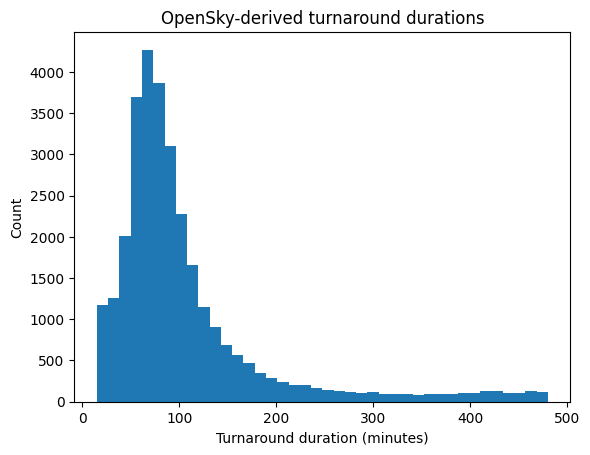

In [5]:

# Quick sanity checks (useful for Milestone 3 validation writeup)
case_counts = event_log.groupby("case:concept:name")["concept:name"].nunique()
print("Cases:", case_counts.size)
print("Activities per case (unique):")
print(case_counts.value_counts().sort_index())

# Turnaround duration distribution
ta = turnarounds["turnaround_minutes"].dropna()
print("\nTurnaround minutes summary:")
print(ta.describe(percentiles=[0.05,0.25,0.5,0.75,0.95]))

# Optional: basic plot
import matplotlib.pyplot as plt
plt.figure()
plt.hist(ta, bins=40)
plt.xlabel("Turnaround duration (minutes)")
plt.ylabel("Count")
plt.title("OpenSky-derived turnaround durations")
plt.show()


In [6]:

# Optional: export to XES for pm4py (if installed)
try:
    import pm4py
    from pm4py.objects.conversion.log import converter as log_converter
    from pm4py.objects.log.util import dataframe_utils
    from pm4py.objects.log.exporter.xes import exporter as xes_exporter

    df_ev = event_log.copy()
    df_ev["time:timestamp"] = pd.to_datetime(df_ev["time:timestamp"], utc=True)
    df_ev = dataframe_utils.convert_timestamp_columns_in_df(df_ev)

    log = log_converter.apply(df_ev, variant=log_converter.Variants.TO_EVENT_LOG)
    OUT_XES = "turnaround_eventlog_opensky.xes"
    xes_exporter.apply(log, OUT_XES)
    print("Saved:", OUT_XES)
except Exception as e:
    print("pm4py export skipped:", e)


c:\Users\amira\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
exporting log, completed traces :: 100%|██████████| 30702/30702 [00:04<00:00, 6771.47it/s]

Saved: turnaround_eventlog_opensky.xes
